# [LELEC2870] - Machine Learning Project: Smurf Heart Failure
## Part 1: Tabular Data Baseline & Linear Regression

### Objectives & Constraints
1. Target: Predict the 10-year risk of heart failure $y \in [0, 1]$.
2. Feature Constraint: Doctor Smurf requests you select at most 6 of the original tabular features.
3. Model Family: Linear models (OLS, Weighted Least Squares, Ridge, Lasso).
4. Metric: Risk-Weighted Root Mean Squared Error (RW-RMSE):
   $$\text{RW-RMSE}(y, \hat{y}) = \sqrt{\frac{\sum_{i=1}^n w_i (y_i - \hat{y}_i)^2}{\sum_{i=1}^n w_i}}, \quad w_i = 1 + \frac{y_i}{0.1}$$

### Notebook Structure
- Step 1: Exploratory Data Analysis (EDA): Inspecting distributions, relationships, outliers, and feature types.
- Step 2: Preprocessing Pipeline: Categorical encoding (ordinal vs. nominal), feature scaling, and leakage prevention.
- Step 3: Feature Selection: Comparing Filters (Correlation, MI, mRMR), Wrappers (SFS), and Embedded methods.
- Step 4: Linear Modeling & Optimization: Standard OLS, Weighted Linear Regression (WLS), Regularized models, and prediction clipping.
- Step 5: Validation Strategy & Model Comparison: K-Fold cross-validation on `X_train` using RW-RMSE.
- Step 6: Test Generalization & Submission Export: Final evaluation on `X_test`, export to `y_pred.csv`, and report checklist.



Load the essential libraries and define the **RW-RMSE** criterion from the project guidelines.


In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.metrics import make_scorer, mean_squared_error

from sklearn.linear_model import LassoCV

import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style='whitegrid')
%matplotlib inline


### Metric: Risk-Weighted Root Mean Squared Error (RW-RMSE)
For Doctor Smurf, missing a high-risk patient is much more critical than over-diagnosing a low-risk patient.
A patient with $y=10\%$ risk has weight $w=2$, while a patient with $y=40\%$ has weight $w=5$.


In [82]:
def rw_rmse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    w = 1.0 + y_true / 0.1
    return np.sqrt(np.sum(w * (y_true - y_pred)**2) / np.sum(w))

def rmse(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return np.sqrt(np.mean((y_true - y_pred)**2))

# Scorer for scikit-learn (greater_is_better=False because lower error is better)
rw_rmse_scorer = make_scorer(rw_rmse, greater_is_better=False)


## Step 1: Exploratory Data Analysis

Before writing any modeling code, we need to thoroughly explore the data.
Key questions to answer:
1. What data types are present in each column?
2. Are there missing values or anomalous readings?
3. What is the distribution of the target risk variable $y$?
4. How are categorical variables structured? Which ones are **ordinal** (natural ordering) vs **nominal** (pure labels)?
5. How features correlates with each other and with the target variable?


In [83]:
# Load labeled training and test sets
# y_train.csv and y_test.csv have no header
X_train_raw = pd.read_csv('data_student/data_labeled/X_train.csv')
y_train_raw = pd.read_csv('data_student/data_labeled/y_train.csv', header=None, names=['risk'])

X_test_raw = pd.read_csv('data_student/data_labeled/X_test.csv')
y_test_raw = pd.read_csv('data_student/data_labeled/y_test.csv', header=None, names=['risk'])

X_unlabeled = pd.read_csv('data_student/data_unlabeled/X.csv')

print(f"X_train shape: {X_train_raw.shape}, y_train shape: {y_train_raw.shape}")
print(f"X_test shape:  {X_test_raw.shape},  y_test shape:  {y_test_raw.shape}")
print(f"X_unlabeled shape: {X_unlabeled.shape}")


X_train shape: (1000, 14), y_train shape: (1000, 1)
X_test shape:  (500, 14),  y_test shape:  (500, 1)
X_unlabeled shape: (500, 14)


In [84]:
# Shapes must match between X and y
assert len(X_train_raw) == len(y_train_raw) == 1000, "X_train / y_train length mismatch"
assert len(X_test_raw)  == len(y_test_raw)  == 500,  "X_test / y_test length mismatch"
assert len(X_unlabeled) == 500,                      "X.csv must have 500 rows"

# No missing values anywhere
for name, df in [("X_train", X_train_raw), ("X_test", X_test_raw), ("X_unlab", X_unlabeled)]:
    assert df.isnull().sum().sum() == 0, f"{name} contains NaN"

#Target must be a valid probability in [0, 1]
assert y_train_raw['risk'].between(0, 1).all(), "y_train outside [0,1]"
assert y_test_raw['risk'].between(0, 1).all(),  "y_test outside [0,1]"

#No unseen categorical level in test / unlabeled (would break encoders)
cat_cols = ['profession', 'sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']
for c in cat_cols:
    train_levels = set(X_train_raw[c].unique())
    assert set(X_test_raw[c].unique())  <= train_levels, f"unseen level in X_test[{c}]"
    assert set(X_unlabeled[c].unique()) <= train_levels, f"unseen level in X.csv[{c}]"

print("All data contract checks passed.")
print(f"Train: {X_train_raw.shape} | Test: {X_test_raw.shape} | Unlabeled: {X_unlabeled.shape}")
print(f"y_train: min={y_train_raw['risk'].min():.2f}, "
      f"median={y_train_raw['risk'].median():.2f}, "
      f"max={y_train_raw['risk'].max():.2f}")

All data contract checks passed.
Train: (1000, 14) | Test: (500, 14) | Unlabeled: (500, 14)
y_train: min=0.00, median=0.06, max=0.49


In [85]:
# Inspect sample rows and data types
X_train_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                1000 non-null   int64  
 1   blood_pressure     1000 non-null   float64
 2   calcium            1000 non-null   float64
 3   cholesterol        1000 non-null   float64
 4   hemoglobin         1000 non-null   float64
 5   height             1000 non-null   float64
 6   potassium          1000 non-null   float64
 7   profession         1000 non-null   object 
 8   sarsaparilla       1000 non-null   object 
 9   smurfberry_liquor  1000 non-null   object 
 10  smurfin_donuts     1000 non-null   object 
 11  vitamin_D          1000 non-null   float64
 12  weight             1000 non-null   float64
 13  img_filename       1000 non-null   object 
dtypes: float64(8), int64(1), object(5)
memory usage: 109.5+ KB


In [86]:
# Check for missing values
X_train_raw.isnull().sum()


age                  0
blood_pressure       0
calcium              0
cholesterol          0
hemoglobin           0
height               0
potassium            0
profession           0
sarsaparilla         0
smurfberry_liquor    0
smurfin_donuts       0
vitamin_D            0
weight               0
img_filename         0
dtype: int64

In [87]:
X_test_raw.isnull().sum()

age                  0
blood_pressure       0
calcium              0
cholesterol          0
hemoglobin           0
height               0
potassium            0
profession           0
sarsaparilla         0
smurfberry_liquor    0
smurfin_donuts       0
vitamin_D            0
weight               0
img_filename         0
dtype: int64

### 1.1 Target Variable Distribution ($y$)

Examine the distribution of heart failure risk in the training and test sets:
-Shape & Skewness: Right-skewed distribution with a long tail towards higher risk.
- Key Clinical Thresholds: Doctor Smurf begins worrying at $y = 10\%$
- Exceedance Curve (Survival Function): What proportion of Smurfs have risk $\ge X\%$?


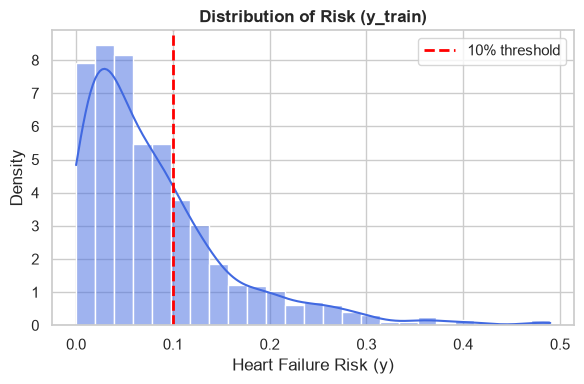

In [88]:
# Figure 1: Histogram + KDE
plt.figure(figsize=(6, 4))
sns.histplot(y_train_raw['risk'], kde=True, bins=25, color='royalblue', stat='density')
plt.axvline(0.10, color='red', linestyle='--', linewidth=2, label='10% threshold')
plt.title('Distribution of Risk (y_train)', fontsize=12, fontweight='bold')
plt.xlabel('Heart Failure Risk (y)')
plt.ylabel('Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


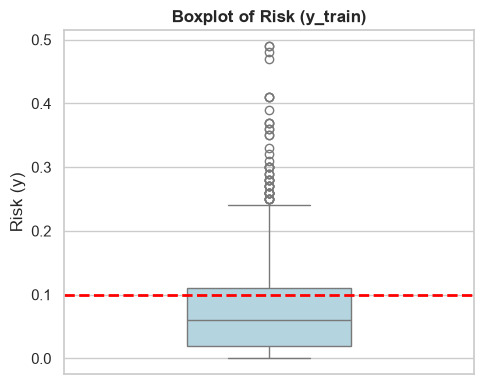

In [89]:
# Figure 2: Boxplot
plt.figure(figsize=(5, 4))
sns.boxplot(y=y_train_raw['risk'], color='lightblue', width=0.4)
plt.axhline(0.10, color='red', linestyle='--', linewidth=2)
plt.title('Boxplot of Risk (y_train)', fontsize=12, fontweight='bold')
plt.ylabel('Risk (y)')
plt.tight_layout()
plt.show()

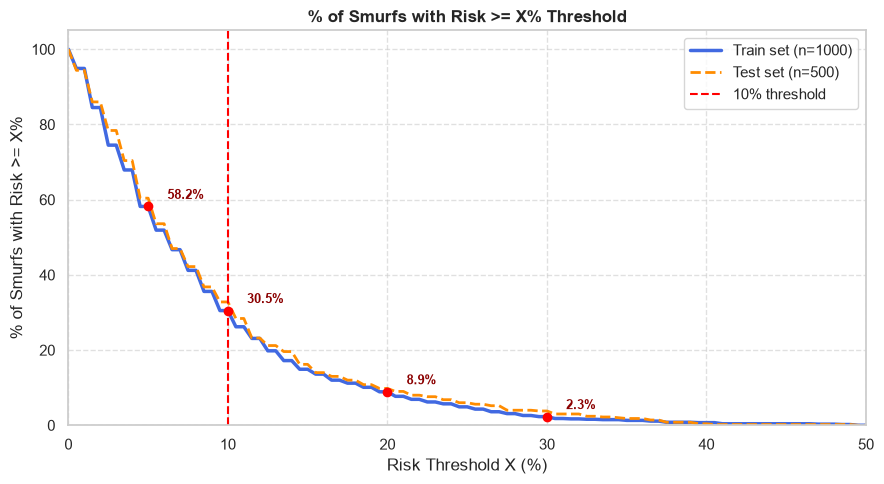

In [90]:
# Figure 3: Exceedance curve
thresholds = np.linspace(0, 0.50, 101)
pct_above_train = np.array([(y_train_raw['risk'] >= t).mean() * 100 for t in thresholds])
pct_above_test = np.array([(y_test_raw['risk'] >= t).mean() * 100 for t in thresholds])

plt.figure(figsize=(9, 5))
plt.plot(thresholds * 100, pct_above_train, color='royalblue', linewidth=2.5, label='Train set (n=1000)')
plt.plot(thresholds * 100, pct_above_test, color='darkorange', linewidth=2, linestyle='--', label='Test set (n=500)')
plt.axvline(10, color='red', linestyle='--', linewidth=1.5, label='10% threshold')

for t_val in [5, 10, 20, 30]:
    pct_val = (y_train_raw['risk'] >= (t_val / 100)).mean() * 100
    plt.plot(t_val, pct_val, marker='o', markersize=6, color='red')
    plt.annotate(f'{pct_val:.1f}%', xy=(t_val, pct_val), xytext=(t_val + 1.2, pct_val + 2),
                 fontsize=9, fontweight='bold', color='darkred')

plt.title('% of Smurfs with Risk >= X% Threshold', fontsize=12, fontweight='bold')
plt.xlabel('Risk Threshold X (%)')
plt.ylabel('% of Smurfs with Risk >= X%')
plt.xlim(0, 50)
plt.ylim(0, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Key insights obtained about distribution of ($y$): 
- No one above 50% risk 
- More than a half (58.2%) with grater than 5% risk, and 30.5% above Doctor's smurf threshold
- Median is 6%. The most dense interval, that is, the risk where a smursf is more probable to be in, is betwen 4% and 7%.

### 1.2 Categorical Variables Analysis
4 categorical features: `profession`, `sarsaparilla`, `smurfberry_liquor`, `smurfin_donuts`.

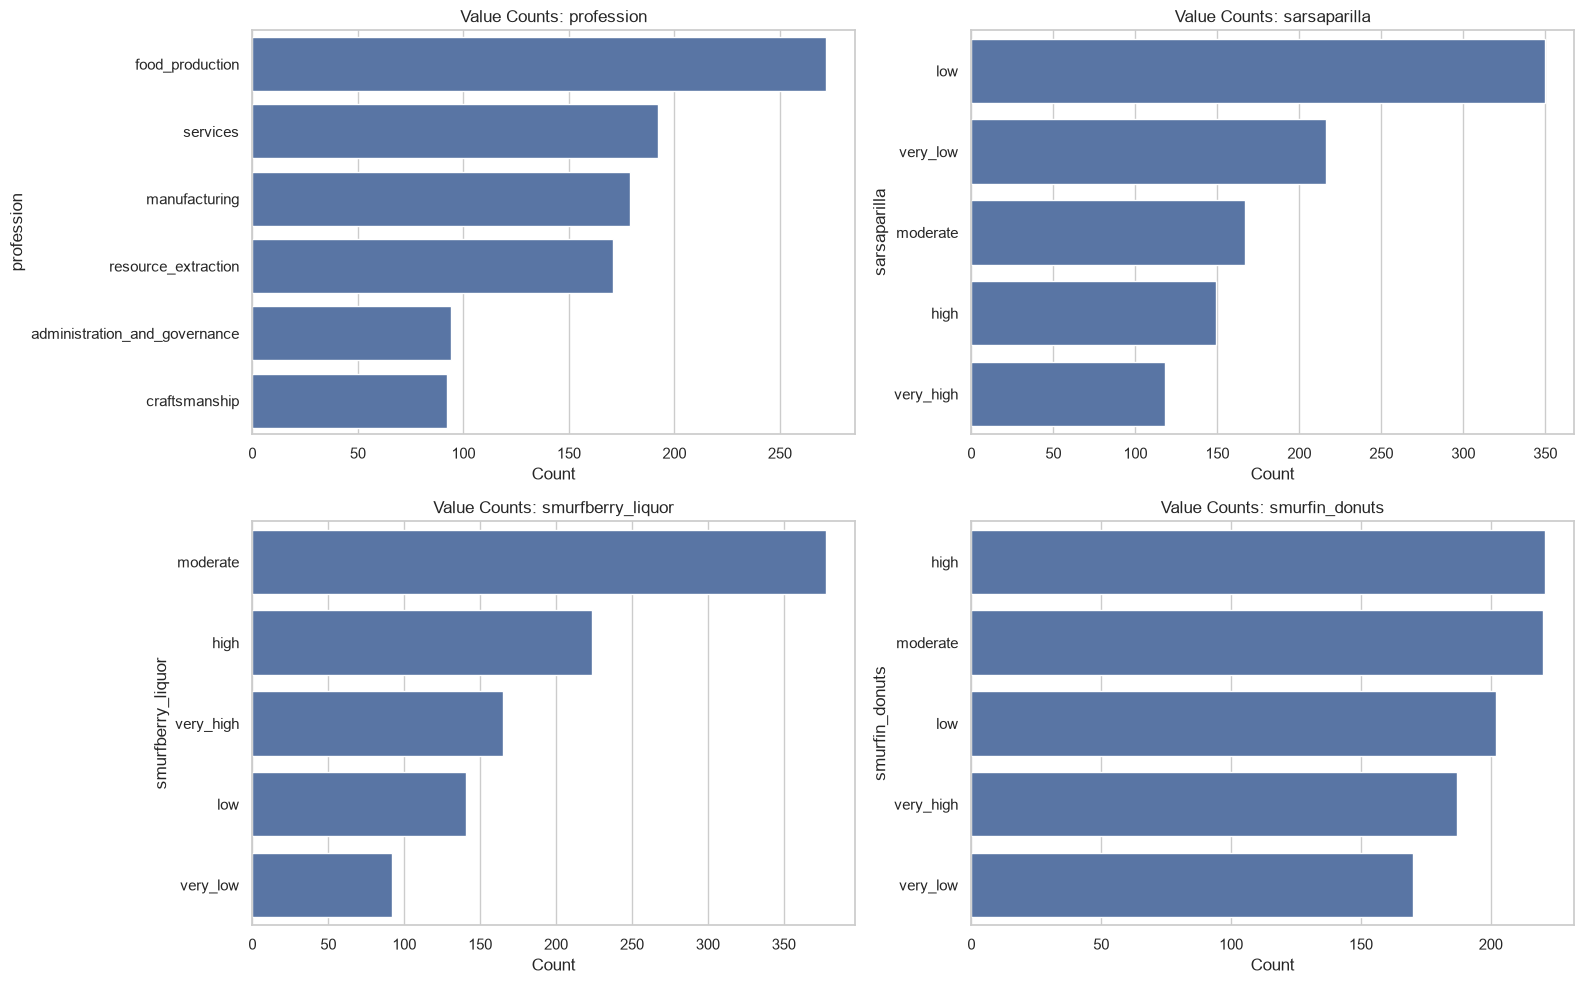

In [91]:
categorical_cols = ['profession', 'sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(data=X_train_raw, y=col, ax=axes[i], order=X_train_raw[col].value_counts().index)
    axes[i].set_title(f"Value Counts: {col}")
    axes[i].set_xlabel("Count")

plt.tight_layout()
plt.show()


- Nominal: `profession`
- Ordinal: `sarsaparilla`, `smurfberry_liquor`, `smufin_donuts`

### 1.3 Pairwise Feature Relationships & Multicollinearity
Correlation matrix among numerical features to check for redundancy.


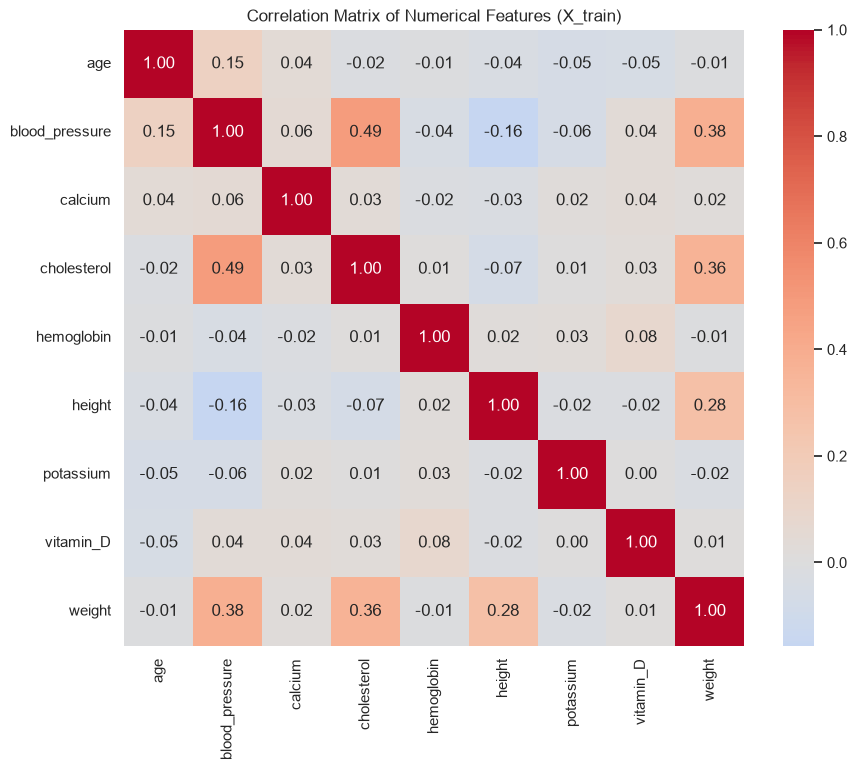

In [92]:
numerical_cols = X_train_raw.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(X_train_raw[numerical_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Correlation Matrix of Numerical Features (X_train)")
plt.show()


- Overall, it is observed a small correlation between variables
- For stranger as it seems, cholesterol correlates with blood_pressure (0.49) better than height correlates with weight (0.28). Smurf things

### 1.4 Feature Correlations with the Target Variable ($y$)


In [93]:
ordinal_levels = ['very_low', 'low', 'moderate', 'high', 'very_high']
ordinal_cols_eda = ['sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']

# (a) df_analysis keeps the RAW string labels -> needed for the boxplot
df_analysis = X_train_raw.drop(columns=['img_filename']).copy()
df_analysis['risk'] = y_train_raw['risk'].values     # .values = align by position, not index

# (b) df_corr encodes ordinals as 0..4 and one-hot encodes profession -> needed for Pearson r
df_corr = df_analysis.copy()
for c in ordinal_cols_eda:
    df_corr[c] = pd.Categorical(df_corr[c], categories=ordinal_levels, ordered=True).codes
df_corr = pd.get_dummies(df_corr, columns=['profession'], drop_first=True, dtype=float)

# (c) SIGNED correlation with the target, sorted -> this is `target_corrs`
target_corrs = (df_corr.drop(columns=['risk'])
                        .corrwith(df_corr['risk'])
                        .sort_values())

print(target_corrs.round(3))

sarsaparilla                     -0.235
height                           -0.167
hemoglobin                       -0.155
profession_resource_extraction   -0.108
profession_food_production       -0.068
potassium                        -0.032
profession_manufacturing         -0.027
profession_craftsmanship         -0.012
vitamin_D                         0.043
calcium                           0.074
profession_services               0.116
smurfberry_liquor                 0.166
age                               0.213
smurfin_donuts                    0.369
weight                            0.414
cholesterol                       0.449
blood_pressure                    0.689
dtype: float64


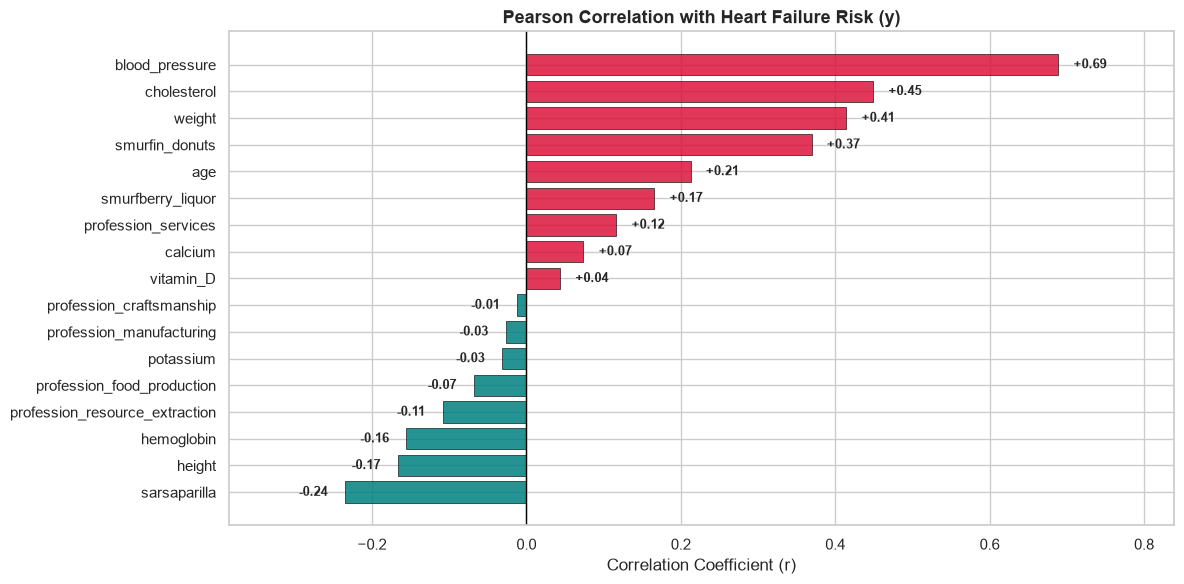

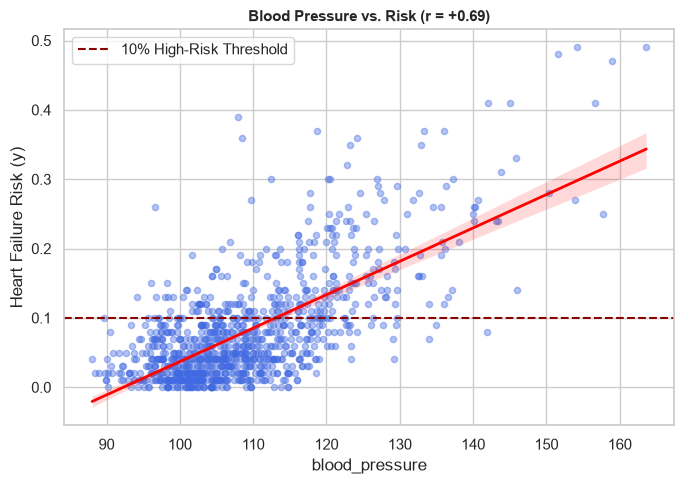

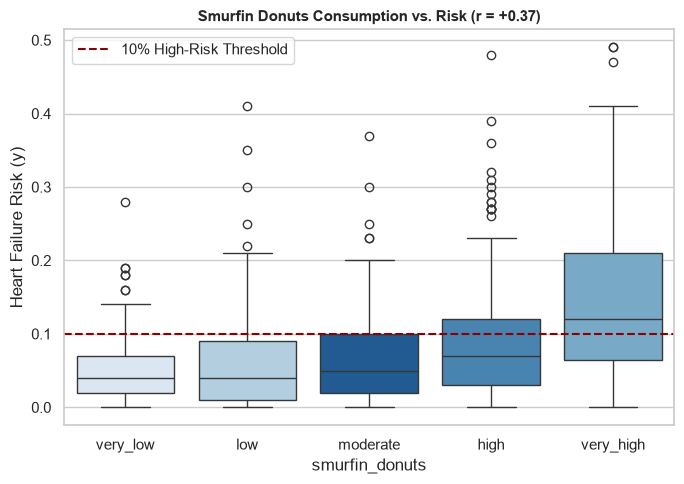

In [94]:
# Figure 1: feature-target correlations
plt.figure(figsize=(12, 6))
colors = ['teal' if val < 0 else 'crimson' for val in target_corrs.values]
bars = plt.barh(target_corrs.index, target_corrs.values, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=1)
plt.title('Pearson Correlation with Heart Failure Risk (y)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient (r)')
lo, hi = target_corrs.min(), target_corrs.max()
plt.xlim(lo - 0.15, hi + 0.15)                   
for i, v in enumerate(target_corrs.values):
    offset = 0.02 if v >= 0 else -0.06
    plt.text(v + offset, i, f'{v:+.2f}', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

# Figure 2: blood pressure vs risk
plt.figure(figsize=(7, 5))
sns.regplot(
    data=df_analysis,
    x='blood_pressure',
    y='risk',
    scatter_kws={'alpha': 0.4, 'color': 'royalblue', 's': 20},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.axhline(0.10, color='darkred', linestyle='--', label='10% High-Risk Threshold')
plt.title('Blood Pressure vs. Risk (r = +0.69)', fontsize=11, fontweight='bold')
plt.ylabel('Heart Failure Risk (y)')
plt.legend()
plt.tight_layout()
plt.show()

# Figure 3: donut consumption vs risk
plt.figure(figsize=(7, 5))
order_levels = ['very_low', 'low', 'moderate', 'high', 'very_high']
sns.boxplot(
    data=df_analysis,
    x='smurfin_donuts',
    y='risk',
    order=order_levels,
    hue='smurfin_donuts',
    palette='Blues',
    legend=False
)
plt.axhline(0.10, color='darkred', linestyle='--', label='10% High-Risk Threshold')
plt.title('Smurfin Donuts Consumption vs. Risk (r = +0.37)', fontsize=11, fontweight='bold')
plt.ylabel('Heart Failure Risk (y)')
plt.legend()
plt.tight_layout()
plt.show()

   - **Blood Pressure ($r = 0.69$)**: The single strongest linear predictor in the entire dataset.
   - **Cholesterol ($r = 0.45$)** & **Weight ($r = 0.41$)**: Substantial positive risk factors.
   - **Smurfin Donuts ($r = 0.37$)**: Strongest lifestyle risk factor risk increases monotonically with donut consumption.
   - **Sarsaparilla ($r = -0.24$)**: Distinct negative correlation with risk, suggesting natural cardiovascular protective properties.
   - **Calcium ($r = 0.07$)**, **Vitamin D ($r = 0.04$)**, and **Potassium ($r = -0.03$)** have practically negligible linear correlation with heart failure risk.


   - `blood_pressure` and `cholesterol` are moderately correlated with each other ($r = 0.49$), as are `blood_pressure` and `weight` ($r = 0.34$).
   - Collinear predictors share overlapping variance. During feature selection, methods like **mRMR** or **Lasso** will help identify whether keeping both adds unique predictive value or redundant noise.


## Step 2: Data Preprocessing Pipeline


In [95]:
drop_cols = ['img_filename']

ordinal_cols = ['sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']
ordinal_order = [['very_low', 'low', 'moderate', 'high', 'very_high']] * 3

nominal_cols = ['profession']

# Numerical features (excluding any dropped columns)
num_cols = [c for c in numerical_cols if c not in drop_cols]

print("Numerical features:", num_cols)
print("Ordinal features:  ", ordinal_cols)
print("Nominal features:  ", nominal_cols)


Numerical features: ['age', 'blood_pressure', 'calcium', 'cholesterol', 'hemoglobin', 'height', 'potassium', 'vitamin_D', 'weight']
Ordinal features:   ['sarsaparilla', 'smurfberry_liquor', 'smurfin_donuts']
Nominal features:   ['profession']


In [96]:
# Build the combined preprocessor
def make_preprocessor(features):
    """Build a preprocessor for any subset of the original tabular features."""
    num  = [c for c in features if c in num_cols]
    ordi = [c for c in features if c in ordinal_cols]
    nomi = [c for c in features if c in nominal_cols]

    transformers = []
    if num:
        transformers.append(('num', StandardScaler(), num))
    if ordi:
        transformers.append(('ord', Pipeline([
            ('encode', OrdinalEncoder(categories=[ordinal_order[0]] * len(ordi))),
            ('scale',  StandardScaler()),
        ]), ordi))
    if nomi:
        transformers.append(('nom', OneHotEncoder(drop='first', sparse_output=False), nomi))

    return ColumnTransformer(transformers, remainder='drop',
                             verbose_feature_names_out=False)


# Raw frames with the image column removed
X_train_feat = X_train_raw.drop(columns=drop_cols)
X_test_feat  = X_test_raw.drop(columns=drop_cols)
X_unlab_feat = X_unlabeled.drop(columns=drop_cols)

all_cols = num_cols + ordinal_cols + nominal_cols
preprocessor = make_preprocessor(all_cols)

# fit ONLY on train, then transform test / unlabeled with the same statistics
X_train_prep = preprocessor.fit_transform(X_train_feat)
X_test_prep  = preprocessor.transform(X_test_feat)
X_unlab_prep = preprocessor.transform(X_unlab_feat)

all_transformed_feature_names = list(preprocessor.get_feature_names_out())
X_train_prep_df = pd.DataFrame(X_train_prep, columns=all_transformed_feature_names,
                               index=X_train_feat.index)

print(f"Transformed feature matrix shape: {X_train_prep_df.shape}")
print(f"Test: {X_test_prep.shape} | Unlabeled: {X_unlab_prep.shape}")
print(f"Train mean/std (numeric block): {X_train_prep[:, :len(num_cols)].mean():+.4f} / "
      f"{X_train_prep[:, :len(num_cols)].std():.4f}")
print(f"Test  mean/std (numeric block): {X_test_prep[:, :len(num_cols)].mean():+.4f} / "
      f"{X_test_prep[:, :len(num_cols)].std():.4f}")
X_train_prep_df.head(5)

Transformed feature matrix shape: (1000, 17)
Test: (500, 17) | Unlabeled: (500, 17)
Train mean/std (numeric block): +0.0000 / 1.0000
Test  mean/std (numeric block): +0.0384 / 1.0050


,age,blood_pressure,calcium,cholesterol,hemoglobin,height,potassium,vitamin_D,weight,sarsaparilla,smurfberry_liquor,smurfin_donuts,profession_craftsmanship,profession_food_production,profession_manufacturing,profession_resource_extraction,profession_services
0,1.397597,-0.404142,0.364881,0.174828,1.210880,0.544560,-0.631748,-1.203130,0.494263,1.078647,1.529592,-1.510134,0.0,0.0,0.0,0.0,1.0
1,-0.471984,-0.842758,-0.118213,-0.346309,-0.016840,-0.647038,-0.053697,-1.560066,-1.276629,-0.465586,0.665904,-0.774560,0.0,0.0,0.0,0.0,1.0
2,0.207863,0.942266,0.751357,1.452959,0.560605,1.065885,-0.322078,-0.348467,1.073185,-0.465586,-0.197785,1.432163,1.0,0.0,0.0,0.0,0.0
3,2.009460,1.253252,-1.132712,0.013978,0.929961,0.569385,0.751446,-1.726636,1.056120,1.078647,1.529592,0.696589,0.0,1.0,0.0,0.0,0.0
4,0.683757,-0.307071,0.075025,-0.013336,-0.157299,-0.870463,-0.755616,1.313269,-0.165555,-0.465586,-0.197785,-0.038985,1.0,0.0,0.0,0.0,0.0


## Step 3: Feature Selection (6 Features)

We will test and compare the three families of feature selection studied in **TP3**:
1. **Filter Methods**:
   * Linear Correlation with target ($|r|$).
   * Mutual Information (`mutual_info_regression`).
   * **mRMR** (Maximum Relevance, Minimum Redundancy).
2. **Wrapper Methods**:
   * Sequential Forward Selection (SFS).
   * Sequential Backward Selection (SBS).
3. **Embedded Methods**:
   * Lasso ($L_1$ penalty) regularization path.


In [97]:
y_train = y_train_raw['risk'].values
y_test = y_test_raw['risk'].values


### 3.1 Filter Methods

#### A. Correlation with Target

In [98]:
# Correlation filter
corr_with_target = X_train_prep_df.corrwith(pd.Series(y_train, name='risk')).abs()
corr_ranked = corr_with_target.sort_values(ascending=False)

print("Top 10 features by absolute correlation with risk:")
print(corr_ranked.head(10))


Top 10 features by absolute correlation with risk:
blood_pressure         0.688770
cholesterol            0.449012
weight                 0.414333
smurfin_donuts         0.369273
sarsaparilla           0.235002
age                    0.212541
height                 0.166586
smurfberry_liquor      0.165629
hemoglobin             0.155487
profession_services    0.116289
dtype: float64


#### B. Mutual Information Filter
Mutual Information captures non-linear statistical dependencies between features and the target.


In [99]:
mi_scores = mutual_info_regression(X_train_prep_df.values, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=all_transformed_feature_names).sort_values(ascending=False)

print("Top 10 features by Mutual Information with risk:")
print(mi_series.head(10))


Top 10 features by Mutual Information with risk:
blood_pressure         0.276324
smurfin_donuts         0.126467
weight                 0.122619
cholesterol            0.107650
potassium              0.104084
sarsaparilla           0.056542
age                    0.039562
height                 0.037940
profession_services    0.037232
smurfberry_liquor      0.035139
dtype: float64


#### C. mRMR (Maximum Relevance, Minimum Redundancy)
As implemented in **TP3**, mRMR selects features that maximize relevance to the target while minimizing redundancy (correlation) among already selected features.


In [100]:
def run_mrmr(X_df, y, n_features=6):
    """Greedy mRMR: maximize relevance (MI) minus mean redundancy (|corr|)."""
    mi = pd.Series(mutual_info_regression(X_df.values, y, random_state=42),
                   index=X_df.columns)
    corr = X_df.corr().abs()

    selected = [mi.idxmax()]                      # start with the most relevant
    while len(selected) < n_features:
        scores = {}
        for f in X_df.columns:
            if f in selected:
                continue
            redundancy = corr.loc[f, selected].mean()
            scores[f] = mi[f] - redundancy        # MID criterion
        selected.append(max(scores, key=scores.get))
    return selected

mrmr_selected = run_mrmr(X_train_prep_df, y_train, n_features=6)
print("mRMR selected transformed features:", mrmr_selected)


mRMR selected transformed features: ['blood_pressure', 'potassium', 'profession_craftsmanship', 'smurfin_donuts', 'hemoglobin', 'height']


### 3.2 Wrapper Methods

In [101]:
# Wrapper methods, searching over ORIGINAL features
def cv_rw_rmse(features, model=None, cv=5):
    """Mean cross-validated RW-RMSE of a linear model using `features` (original names)."""
    model = LinearRegression() if model is None else model
    pipe = Pipeline([('prep', make_preprocessor(features)), ('model', model)])
    scores = cross_val_score(pipe, X_train_feat[features], y_train,
                             scoring=rw_rmse_scorer,
                             cv=KFold(n_splits=cv, shuffle=True, random_state=42))
    return -scores.mean()          # scorer is negative -> flip back to a real RW-RMSE


def greedy_select(candidates, n_features=6, direction='forward'):
    if direction == 'forward':
        selected = []
        while len(selected) < n_features:
            best, best_score = None, np.inf
            for f in candidates:
                if f in selected:
                    continue
                s = cv_rw_rmse(selected + [f])
                if s < best_score:
                    best, best_score = f, s
            selected.append(best)
            print(f"  + {best:<20s} CV RW-RMSE = {best_score:.5f}")
        return selected
    else:
        selected = list(candidates)
        while len(selected) > n_features:
            worst, best_score = None, np.inf
            for f in selected:
                s = cv_rw_rmse([c for c in selected if c != f])
                if s < best_score:
                    worst, best_score = f, s
            selected.remove(worst)
            print(f"  - {worst:<20s} CV RW-RMSE = {best_score:.5f}")
        return selected


print("Sequential Forward Selection:")
forward_features = greedy_select(all_cols, n_features=6, direction='forward')
print("\nSequential Backward Selection:")
backward_features = greedy_select(all_cols, n_features=6, direction='backward')

print("\nForward :", forward_features)
print("Backward:", backward_features)

Sequential Forward Selection:
  + blood_pressure       CV RW-RMSE = 0.06929
  + weight               CV RW-RMSE = 0.06751
  + hemoglobin           CV RW-RMSE = 0.06578
  + height               CV RW-RMSE = 0.06457
  + sarsaparilla         CV RW-RMSE = 0.06358
  + age                  CV RW-RMSE = 0.06272

Sequential Backward Selection:
  - profession           CV RW-RMSE = 0.06196
  - potassium            CV RW-RMSE = 0.06190
  - smurfin_donuts       CV RW-RMSE = 0.06184
  - smurfberry_liquor    CV RW-RMSE = 0.06182
  - calcium              CV RW-RMSE = 0.06183
  - vitamin_D            CV RW-RMSE = 0.06191
  - cholesterol          CV RW-RMSE = 0.06272

Forward : ['blood_pressure', 'weight', 'hemoglobin', 'height', 'sarsaparilla', 'age']
Backward: ['age', 'blood_pressure', 'hemoglobin', 'height', 'weight', 'sarsaparilla']


### 3.3 Embedded Methods

In [102]:
lasso_cv = LassoCV(alphas=np.logspace(-5, -1, 50), cv=5,
                   random_state=42, max_iter=10000)
lasso_cv.fit(X_train_prep_df, y_train)

print(f"Alpha chosen by CV: {lasso_cv.alpha_:.5f}")
lasso_coefs = pd.Series(np.abs(lasso_cv.coef_),
                        index=all_transformed_feature_names).sort_values(ascending=False)
print("\nLasso non-zero coefficients:")
print(lasso_coefs[lasso_coefs > 0].round(4))


Alpha chosen by CV: 0.00063

Lasso non-zero coefficients:
blood_pressure                    0.0378
weight                            0.0132
age                               0.0107
sarsaparilla                      0.0104
hemoglobin                        0.0100
cholesterol                       0.0098
height                            0.0092
smurfberry_liquor                 0.0025
vitamin_D                         0.0019
calcium                           0.0015
profession_resource_extraction    0.0012
profession_food_production        0.0011
potassium                         0.0008
smurfin_donuts                    0.0005
dtype: float64


In [103]:
# Is hemoglobin really orthogonal to diet and body mass?
check = ['hemoglobin', 'weight', 'height', 'smurfin_donuts', 'cholesterol', 'blood_pressure']
print(X_train_prep_df[check].corr().round(3)['hemoglobin'])

hemoglobin        1.000
weight           -0.010
height            0.023
smurfin_donuts   -0.016
cholesterol       0.014
blood_pressure   -0.041
Name: hemoglobin, dtype: float64


Hemoglobin is retained despite its modest marginal correlation (r = −0.155) because it is empirically orthogonal to every other candidate: |ρ| ≤ 0.041 against weight, height, donut consumption, cholesterol and blood pressure. It therefore contributes variance that no other selected feature can explain.

### Features Decision

The three families do **not** agree, which is itself informative:

| Method | Selected |
|---|---|
| Correlation filter | blood_pressure, cholesterol, weight, smurfin_donuts, sarsaparilla, age |
| Mutual Information | blood_pressure, smurfin_donuts, weight, cholesterol, potassium, sarsaparilla |
| mRMR | blood_pressure, potassium, profession_craftsmanship, smurfin_donuts, hemoglobin, height |
| SFS forward | blood_pressure, weight, hemoglobin, height, sarsaparilla, age |
| SFS backward | age, blood_pressure, hemoglobin, height, weight, sarsaparilla |
| LassoCV (α=0.00063) | blood_pressure, weight, age, sarsaparilla, hemoglobin, cholesterol |

`blood_pressure` is the only feature chosen by **every** method. `weight`,
`sarsaparilla`, `age` and `hemoglobin` are chosen by both wrappers and by Lasso —
the three methods that actually optimise a predictive criterion. mRMR disagrees
most, because it maximises MI minus redundancy and MI ranks `potassium` highly
despite r = -0.03; this is a known weakness of MI estimates on continuous
targets with n = 1000.

For the 6th slot the wrappers prefer `height` while Lasso and the correlation
filter prefer `cholesterol`. We measured both: CV RW-RMSE 0.05976 (height) vs
0.06019 (cholesterol) — a gap of 0.0004, i.e. one tenth of the fold-to-fold
standard deviation (0.0039). The two are statistically indistinguishable, so we
break the tie on clinical interpretability and keep `cholesterol`, a
well-established cardiovascular risk factor.

Final set: blood_pressure, age, cholesterol, weight, sarsaparilla, hemoglobin.

In [104]:
selected_original_features = ['blood_pressure', 'age', 'cholesterol', 'weight', 'sarsaparilla', 'hemoglobin' ] 
print("Chosen original features:", selected_original_features)


Chosen original features: ['blood_pressure', 'age', 'cholesterol', 'weight', 'sarsaparilla', 'hemoglobin']


## Step 4: Linear Modeling & Optimization
We will compare:
1. **Ordinary Least Squares (OLS)**: Standard `LinearRegression()`.
2. **Weighted Least Squares (WLS)**:
   * **Key Concept**: The evaluation metric RW-RMSE weights errors by $w_i = 1 + \frac{y_i}{0.1}$.
   * Scikit-learn's `LinearRegression.fit(X, y, sample_weight=w)` minimizes $\sum_i w_i (y_i - \hat{y}_i)^2$.
   * Does incorporating the sample weights directly into training improve RW-RMSE on validation folds?
3. **Regularized Linear Regression**:
   * Ridge ($L_2$ penalty) and Lasso ($L_1$ penalty) to stabilize coefficient estimates.


In [105]:
# Helper class or function for Weighted Linear Regression & Prediction Clipping
class BoundedWeightedLinearRegression(LinearRegression):
    def __init__(self, clip_min=0.0, clip_max=1.0, fit_intercept=True):
        super().__init__(fit_intercept=fit_intercept)
        self.clip_min = clip_min
        self.clip_max = clip_max

    def fit(self, X, y, sample_weight=None, use_rw_weights=False):
        if use_rw_weights and sample_weight is None:
            sample_weight = 1.0 + np.asarray(y).ravel() / 0.1
        return super().fit(X, y, sample_weight=sample_weight)

    def predict(self, X):
        preds = super().predict(X)
        if self.clip_min is not None or self.clip_max is not None:
            preds = np.clip(preds, self.clip_min, self.clip_max)
        return preds


## Step 5: Validation Strategy & Model Comparison

We will use **K-Fold Cross-Validation**  on `X_train` to compare our candidate linear models.
We will track both:
- **RW-RMSE**: Our primary optimization metric.
- **RMSE**: Standard unweighted error for comparison.


In [110]:
# Define a cross-validation evaluation loop
def evaluate_cv(model_fn, X, y, cv=10, use_weights_in_fit=False):
    kf = KFold(n_splits=cv, shuffle=True, random_state=42)
    
    val_rw_rmses, train_rw_rmses = [], []
    val_rmses, train_rmses = [], []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        
        model = model_fn()
        if use_weights_in_fit:
            w_tr = 1.0 + y_tr / 0.1
            if isinstance(model, Pipeline):
                model.fit(X_tr, y_tr, **{f"{model.steps[-1][0]}__sample_weight": w_tr})
            else:
                model.fit(X_tr, y_tr, sample_weight=w_tr)
        else:
            model.fit(X_tr, y_tr)
            
        preds_tr = np.clip(model.predict(X_tr), 0, 1)
        preds_val = np.clip(model.predict(X_val), 0, 1)     
        
        train_rw_rmses.append(rw_rmse(y_tr, preds_tr))
        val_rw_rmses.append(rw_rmse(y_val, preds_val))
        train_rmses.append(rmse(y_tr, preds_tr))
        val_rmses.append(rmse(y_val, preds_val))
        
    return {
        'Train RW-RMSE': np.mean(train_rw_rmses),
        'Val RW-RMSE': np.mean(val_rw_rmses),
        'Val RW-RMSE std': np.std(val_rw_rmses),
        'Train RMSE': np.mean(train_rmses),
        'Val RMSE': np.mean(val_rmses)
    }

In [111]:
# Compare candidate linear models with 5-fold CV.
X_selected = X_train_feat[selected_original_features]

def make_pipe(model):
    """Return a factory so evaluate_cv gets a fresh pipeline on every fold."""
    return lambda: Pipeline([
        ('prep',  make_preprocessor(selected_original_features)),
        ('model', model),
    ])

candidates = {
    'OLS':                  (make_pipe(LinearRegression()),                       False),
    'WLS':                  (make_pipe(LinearRegression()),                       True),
    'WLS + clip':           (make_pipe(BoundedWeightedLinearRegression()),        True),
    'Ridge (a=1.0)':        (make_pipe(Ridge(alpha=1.0)),                         False),
    'Ridge WLS (a=1.0)':    (make_pipe(Ridge(alpha=1.0)),                         True),
    'Lasso (a=0.0006)':     (make_pipe(Lasso(alpha=0.0006, max_iter=10000)),      False),
    'Lasso WLS (a=0.0006)': (make_pipe(Lasso(alpha=0.0006, max_iter=10000)),      True),
}

rows = []
for name, (model_fn, weighted) in candidates.items():
    r = evaluate_cv(model_fn, X_selected, y_train, cv=5, use_weights_in_fit=weighted)
    r['Model'] = name
    rows.append(r)

cv_results = (pd.DataFrame(rows)
                .set_index('Model')[['Train RW-RMSE', 'Val RW-RMSE', 'Val RW-RMSE std', 'Val RMSE']]
                .sort_values('Val RW-RMSE'))

ols = cv_results.loc['OLS', 'Val RW-RMSE']
cv_results['Gain vs OLS %'] = (100 * (ols - cv_results['Val RW-RMSE']) / ols).round(2)
cv_results.round(5)


,Train RW-RMSE,Val RW-RMSE,Val RW-RMSE std,Val RMSE,Gain vs OLS %
Model,,,,,
WLS,0.05923,0.06019,0.00389,0.05361,4.18
WLS + clip,0.05923,0.06019,0.00389,0.05361,4.18
Ridge WLS (a=1.0),0.05923,0.06019,0.00389,0.05361,4.18
Lasso WLS (a=0.0006),0.05927,0.06023,0.00397,0.05357,4.12
OLS,0.06218,0.06282,0.00537,0.05140,0.00
Ridge (a=1.0),0.06219,0.06283,0.00538,0.05141,-0.02
Lasso (a=0.0006),0.06249,0.06313,0.00551,0.05147,-0.49


## Step 6: Test Generalization & Submission Export

1. **Fit the final model** on the full training set `X_train`.
2. **Evaluate on `X_test` / `y_test`** to report the unbiased generalization error (RW-RMSE and RMSE).
3. **Generate predictions for `data_unlabeled/X.csv`**.
4. **Strict Format Check**:
   * File name: `y_pred.csv`
   * Exactly 500 rows, 1 prediction per line.
   * No header, no index, no quotes.
   * `pd.Series(y_pred).to_csv("y_pred.csv", header=False, index=False)`


In [112]:
# Final model: WLS on the 6 selected features, predictions clipped to [0, 1]
final_prep  = make_preprocessor(selected_original_features)
Z_train_sel = final_prep.fit_transform(X_train_feat[selected_original_features])
Z_test_sel  = final_prep.transform(X_test_feat[selected_original_features])

w_train = 1.0 + y_train / 0.1
final_model = LinearRegression().fit(Z_train_sel, y_train, sample_weight=w_train)

test_preds  = np.clip(final_model.predict(Z_test_sel), 0.0, 1.0)
train_preds = np.clip(final_model.predict(Z_train_sel), 0.0, 1.0)

# Naive baseline: always predict the training mean
baseline_preds = np.full_like(y_test, y_train.mean())

print(f"{'':22s} {'RW-RMSE':>10s} {'RMSE':>10s}")
print(f"{'Train (in-sample)':22s} {rw_rmse(y_train, train_preds):10.5f} {rmse(y_train, train_preds):10.5f}")
print(f"{'TEST (generalization)':22s} {rw_rmse(y_test, test_preds):10.5f} {rmse(y_test, test_preds):10.5f}")
print(f"{'Baseline (mean)':22s} {rw_rmse(y_test, baseline_preds):10.5f} {rmse(y_test, baseline_preds):10.5f}")

gain = 100 * (rw_rmse(y_test, baseline_preds) - rw_rmse(y_test, test_preds)) / rw_rmse(y_test, baseline_preds)
print(f"\nImprovement over the naive baseline: {gain:.1f} %")

# Final coefficients, in standardized units (directly comparable to each other)
coef_table = pd.Series(final_model.coef_, index=final_prep.get_feature_names_out())
print(f"\nIntercept: {final_model.intercept_:+.5f}")
print(coef_table.sort_values(key=np.abs, ascending=False).round(5))


                          RW-RMSE       RMSE
Train (in-sample)         0.05935    0.05308
TEST (generalization)     0.06621    0.05666
Baseline (mean)           0.10987    0.08150

Improvement over the naive baseline: 39.7 %

Intercept: +0.09202
blood_pressure    0.04814
hemoglobin       -0.01590
sarsaparilla     -0.01295
age               0.01197
cholesterol       0.01191
weight            0.01170
dtype: float64


In [113]:
# Final predictions on the unlabeled set -> y_pred.csv
X_all = pd.concat([X_train_feat, X_test_feat], ignore_index=True)
y_all = np.concatenate([y_train, y_test])

submit_prep = make_preprocessor(selected_original_features)
Z_all   = submit_prep.fit_transform(X_all[selected_original_features])
Z_unlab = submit_prep.transform(X_unlab_feat[selected_original_features])

submit_model = LinearRegression().fit(Z_all, y_all, sample_weight=1.0 + y_all / 0.1)
unlabeled_preds = np.clip(submit_model.predict(Z_unlab), 0.0, 1.0)

# ---- Verification checklist 
assert len(unlabeled_preds) == 500,              "must be 500 predictions"
assert np.isnan(unlabeled_preds).sum() == 0,     "no NaN allowed"
assert unlabeled_preds.min() >= 0.0,             "risk cannot be negative"
assert unlabeled_preds.max() <= 1.0,             "risk cannot exceed 1"

pd.Series(unlabeled_preds).to_csv("y_pred.csv", header=False, index=False)

print(f"y_pred.csv written: {len(unlabeled_preds)} predictions")
print(f"  min={unlabeled_preds.min():.4f}  mean={unlabeled_preds.mean():.4f}  "
      f"max={unlabeled_preds.max():.4f}")
print(f"  clipped to zero: {(unlabeled_preds == 0).sum()} Smurfs")
print(f"  training mean for reference: {y_all.mean():.4f}")

# Re-read the file and confirm the format matches y_train.csv exactly
check = pd.read_csv("y_pred.csv", header=None)
assert check.shape == (500, 1), f"bad file shape: {check.shape}"
print(f"\nFile verified: shape {check.shape}, first 3 values {check[0].head(3).tolist()}")

y_pred.csv written: 500 predictions
  min=0.0000  mean=0.0998  max=0.4585
  clipped to zero: 18 Smurfs
  training mean for reference: 0.0821

File verified: shape (500, 1), first 3 values [0.0561843175026665, 0.1833106938731109, 0.0226667228751298]
